# 03 · Registration: do spots sit on the H&E image correctly? (R1)

**What this notebook does.** It draws every spot, at its true physical size, on the H&E images distributed in GEO,
to check that spot coordinates and image agree in position, orientation and scale. This is the basis for any
image-RNA pairing (notebook 05).

**Coordinate systems used (and how they relate):**

| System | Unit | Source | Conversion |
|---|---|---|---|
| Array grid | (`array_row`, `array_col`) | `tissue_positions.csv` | fixed Visium layout; neighbours in a row are 2 columns apart and 100 µm apart |
| Full-resolution pixels | (`pxl_row_in_fullres`, `pxl_col_in_fullres`) | `tissue_positions.csv` | pixels of the original microscope image, **which is not in GEO** |
| hires image pixels | (x, y) | `tissue_hires_image.png` (~2000 px) | x = col × `tissue_hires_scalef`, y = row × `tissue_hires_scalef` |
| aligned_fiducials pixels | (x, y) | `aligned_fiducials.jpg` (3000 px) | assumed x = col × `regist_target_img_scalef` (tested in 3.3) |
| Micrometres | (x_um, y_um) | computed | full-res pixel × `um_per_fullres_px` (spot grid, notebook 01) |

Images use the usual convention: origin at the top-left, x to the right (columns), y downwards (rows).

| | |
|---|---|
| **Inputs** | processed `.h5ad` files, raw images, `manifests/capture_areas.csv` |
| **Outputs** | `figures/03_registration/*.png`, `manifests/fiducials_alignment_check.csv` |

In [1]:
# --- Setup: make src/ importable, load helpers, define all paths -------------
import sys
from pathlib import Path
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacemel_io as sio
import spacemel_plots as splot

P = sio.get_paths()
sio.ensure_output_dirs(P)
FIG = P["figures"] / "03_registration"
FIG.mkdir(parents=True, exist_ok=True)
MAN = P["manifests"]
pd.set_option("display.max_columns", 60, "display.width", 220, "display.max_colwidth", 80)
print("repo      :", P["repo"])
print("raw data  :", P["raw"])
print("figures ->:", FIG)
print("manifests:", MAN)

repo      : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval
raw data  : C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\data\GSE298774\raw
figures ->: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\03_registration
manifests: C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\manifests


In [2]:
usable = sio.usable_sections(P)
capture_areas = pd.read_csv(MAN / "capture_areas.csv").set_index("gsm")
capture_areas[["sections", "array_size", "um_per_fullres_px", "um_per_hires_px", "um_per_fiducials_px",
               "spot55um_in_hires_px", "spot_diameter_fullres_um"]]

,sections,array_size,um_per_fullres_px,um_per_hires_px,um_per_fiducials_px,spot55um_in_hires_px,spot_diameter_fullres_um
gsm,,,,,,,
GSM9022963,A17;A2,11 mm,0.3663,11.09,3.70,5.0,59.9
GSM9022964,A7,6.5 mm,0.2198,5.12,1.71,10.8,70.0
GSM9022965,A21,6.5 mm,0.2941,7.80,2.60,7.1,70.0
GSM9022966,A16;A23,11 mm,0.3676,11.78,3.93,4.7,60.1
GSM9022967,A22;A24,11 mm,0.3861,11.27,3.76,4.9,60.0
GSM9022968,A34,11 mm,0.2825,8.90,2.97,6.2,60.0
GSM9022969,B1;B38ex,11 mm,0.3236,8.73,2.91,6.3,59.9
GSM9022970,B4,11 mm,0.3401,9.07,3.02,6.1,59.9
GSM9022971,B13;B8,11 mm,0.2933,8.80,2.93,6.3,60.0


## 3.1 · Overlay per section on the hires image

Left: the whole section with all in-tissue spots as outlines. Right: a 1.5 mm × 1.5 mm window around the median spot
position, spots coloured by log(1 + UMI counts), to judge whether spot positions follow tissue edges and structures.
Circles are drawn at 55 µm diameter in image pixels, so their size is itself a scale check. Three sections are shown here as examples: D20 (high pass rate, 6.5 mm capture area), A24 (high depth) and B8 (lowest QC pass rate). The figures for all 18 sections are saved in `figures/03_registration/<GSM>_<section>_hires_overlay.png`.

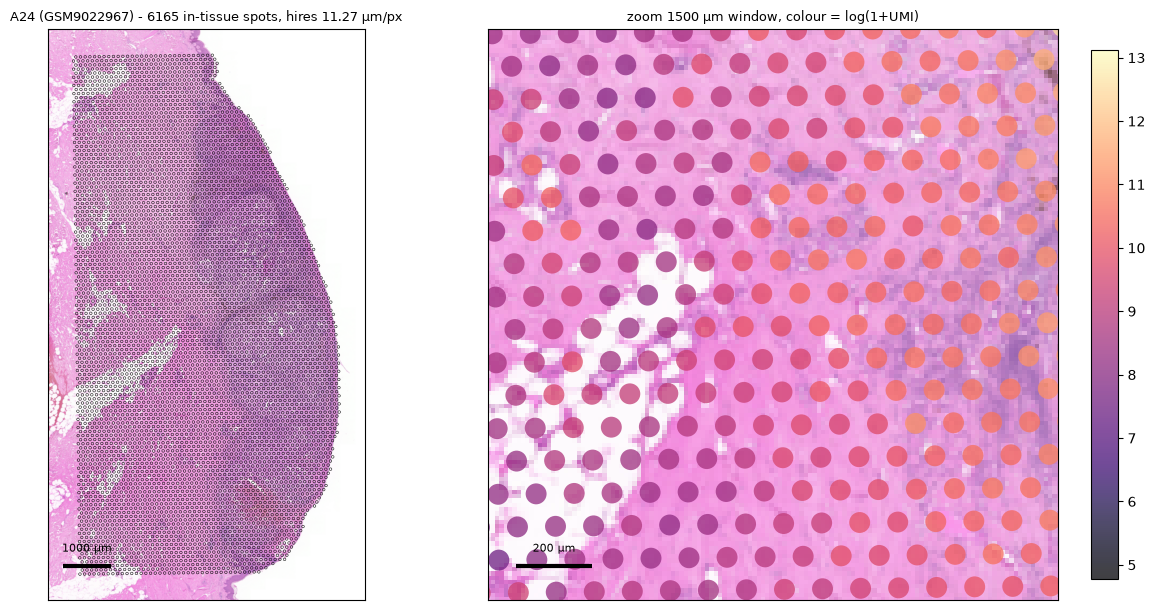

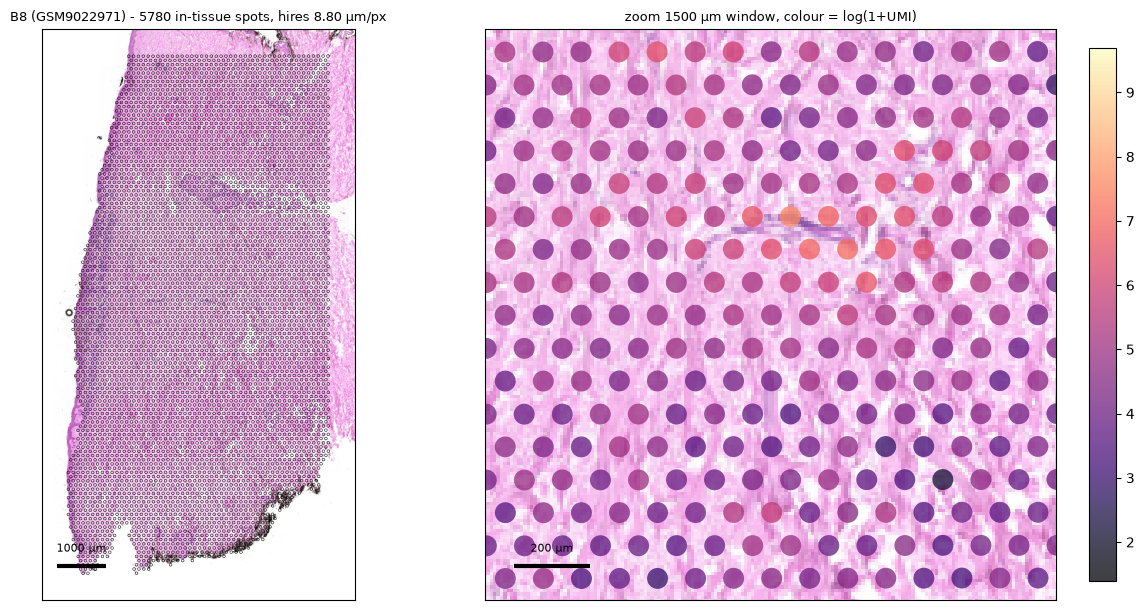

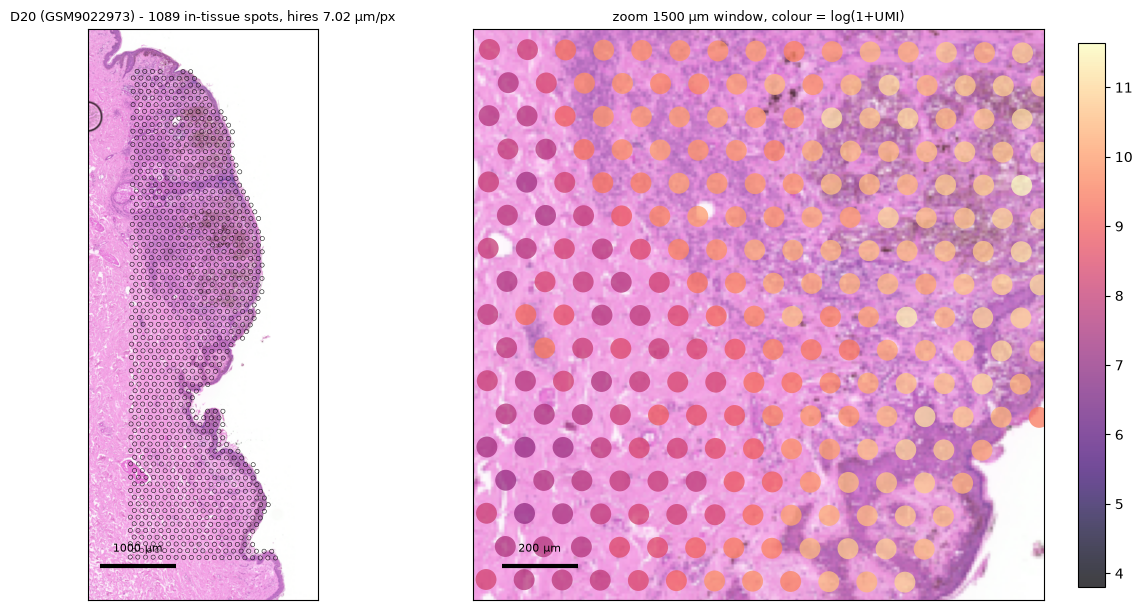

saved 18 overlay figures to C:\Users\Kerekes Kinga\Downloads\multimodal-retrieval\figures\03_registration; shown here: D20, A24, B8


In [3]:
WINDOW_UM = 1500
SHOW = ["D20", "A24", "B8"]
for g, s in usable:
    a = sio.read_processed(P, g, s)
    img, x, y, um = sio.section_image(P, a, "hires")
    d = sio.SPOT_DIAMETER_UM / um
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2))
    splot.section_map(ax1, img, x, y, d, um, edge_only=True, color="black",
                      title=f"{s} ({g}) - {a.n_obs} in-tissue spots, hires {um:.2f} µm/px")
    coll = splot.section_map(ax2, img, x, y, d, um, values=np.log1p(a.obs.total_counts), cmap="magma",
                             scalebar_um=None, alpha=0.75, title=f"zoom {WINDOW_UM} µm window, colour = log(1+UMI)")
    cx, cy, h = np.median(x), np.median(y), WINDOW_UM / um / 2
    ax2.set_xlim(cx - h, cx + h); ax2.set_ylim(cy + h, cy - h)
    splot.scalebar(ax2, 200, um)
    fig.colorbar(coll, ax=ax2, fraction=0.04)
    fig.tight_layout()
    splot.savefig(fig, FIG / f"{g}_{s}_hires_overlay.png")
    if s in SHOW:
        plt.show()
    plt.close(fig)
print(f"saved {len(usable)} overlay figures to {FIG}; shown here: {', '.join(SHOW)}")

## 3.2 · How sharp is the hires image?

The hires image is the only H&E copy in GEO that certainly covers every section. Its resolution limits what any H&E
patch can show: if one pixel covers about the size of a cell, individual cells cannot be resolved.
This table lists, per capture area, the pixel size and the number of pixels across one 55 µm spot. 

In [4]:
capture_areas[["um_per_hires_px", "spot55um_in_hires_px", "um_per_fiducials_px"]].assign(
    spot55um_in_fiducials_px=lambda d: (sio.SPOT_DIAMETER_UM / d.um_per_fiducials_px).round(1))

,um_per_hires_px,spot55um_in_hires_px,um_per_fiducials_px,spot55um_in_fiducials_px
gsm,,,,
GSM9022963,11.09,5.0,3.70,14.9
GSM9022964,5.12,10.8,1.71,32.2
GSM9022965,7.80,7.1,2.60,21.2
GSM9022966,11.78,4.7,3.93,14.0
GSM9022967,11.27,4.9,3.76,14.6
GSM9022968,8.90,6.2,2.97,18.5
GSM9022969,8.73,6.3,2.91,18.9
GSM9022970,9.07,6.1,3.02,18.2
GSM9022971,8.80,6.3,2.93,18.8


## 3.3 · Can `aligned_fiducials.jpg` be used as a sharper image?

`aligned_fiducials.jpg` is 3000 × 3000 px and its scale factor (`regist_target_img_scalef`) is larger than the hires
one, so if spots map onto it with that scale factor, it would be ~3× sharper. This is **not documented for this
dataset** and is tested here per capture area:

* `frac_spots_inside_image`: fraction of in-tissue spots whose transformed position lies inside the image;
* side-by-side figure: the same spots on hires (left) and on aligned_fiducials (right). Alignment is acceptable only
  if the circles cover the same tissue in both.

The image may also show the fiducial markers drawn by Space Ranger and may be the CytAssist camera image rather
than the microscope H&E; the figure is the evidence for which it is. 

Two capture areas are shown as examples (GSM9022967, GSM9022971); the figures for all 11 are saved in `figures/03_registration/<GSM>_fiducials_alignment_test.png`. The table covers all capture areas.

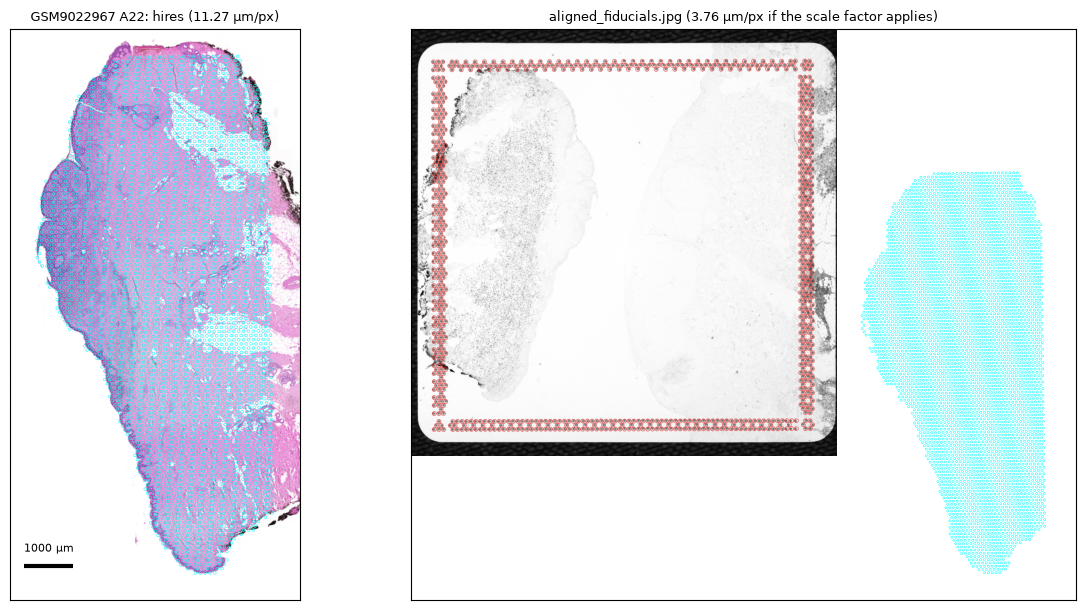

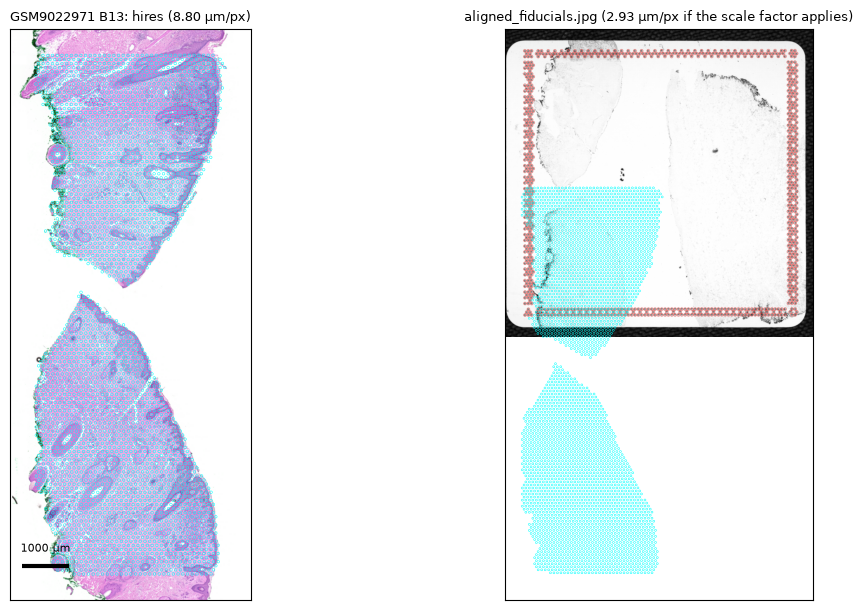

,gsm,section_shown,fiducials_image_hw,um_per_fiducials_px,frac_spots_inside_image
0,GSM9022963,A17,"(3000, 3000)",3.70,0.026
1,GSM9022964,A7,"(3000, 3000)",1.71,0.638
2,GSM9022965,A21,"(3000, 3000)",2.60,0.299
3,GSM9022966,A16,"(3000, 3000)",3.93,0.089
4,GSM9022967,A22,"(3000, 3000)",3.76,0.000
5,GSM9022968,A34,"(3000, 3000)",2.97,0.000
6,GSM9022969,B1,"(3000, 3000)",2.91,0.019
7,GSM9022970,B4,"(3000, 3000)",3.02,0.114
8,GSM9022971,B13,"(3000, 3000)",2.93,0.454
9,GSM9022972,B14,"(3000, 3000)",2.86,0.000


In [5]:
rows = []
SHOW_GSM = ["GSM9022967", "GSM9022971"]
for gsm in sorted({g for g, _ in usable}):
    s = next(ss for gg, ss in usable if gg == gsm)
    a = sio.read_processed(P, gsm, s)
    img_h, xh, yh, um_h = sio.section_image(P, a, "hires")
    img_f, xf, yf, um_f = sio.section_image(P, a, "fiducials")
    inside = (xf >= 0) & (yf >= 0) & (xf < img_f.shape[1]) & (yf < img_f.shape[0])
    rows.append({"gsm": gsm, "section_shown": s, "fiducials_image_hw": img_f.shape[:2],
                 "um_per_fiducials_px": round(um_f, 2), "frac_spots_inside_image": round(inside.mean(), 3)})
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2))
    splot.section_map(ax1, img_h, xh, yh, sio.SPOT_DIAMETER_UM / um_h, um_h, edge_only=True, color="cyan",
                      title=f"{gsm} {s}: hires ({um_h:.2f} µm/px)")
    ax2.imshow(img_f)
    splot.spot_circles(ax2, xf, yf, sio.SPOT_DIAMETER_UM / um_f, color="cyan", edge_only=True)
    ax2.set_title(f"aligned_fiducials.jpg ({um_f:.2f} µm/px if the scale factor applies)", fontsize=9)
    ax2.set_xticks([]); ax2.set_yticks([])
    fig.tight_layout()
    splot.savefig(fig, FIG / f"{gsm}_fiducials_alignment_test.png")
    if gsm in SHOW_GSM:
        plt.show()    
    plt.close(fig)
fid_check = pd.DataFrame(rows)
fid_check.to_csv(MAN / "fiducials_alignment_check.csv", index=False)
fid_check

## 3.4 · Comparison with the published figures

The paper shows H&E with spot annotations in **Fig. 1B–E and 1G** (one lesion; H&E, SOX10, p16, PRAME, and spots
coloured by most abundant cell type with nevus "N" and melanoma "M" areas), **Supplementary Fig. S1E** (three
lesions; nevus / melanoma 1 / melanoma 2 spots) and **Supplementary Fig. S4** (15 lesions, panels A–O, same colouring).
**None of these legends names the patient**, and the panels are rotated, cropped and resized, so a lesion cannot be
matched to a section with certainty. The published spot colours come from the authors' deconvolution, which is not
in GEO.

| Our section(s) | Published panel | What agrees | What differs | What cannot be verified |
|---|---|---|---|---|
| all 18 | Fig. 1B–G, Supp. Fig. S1E, Supp. Fig. S4 A–O | Published panels show skin sections with spots on the lesion area, as in our overlays | Published panels are unlabelled, rotated (skin surface horizontal) and cropped to the lesion, and show only nevus / Melanoma 1 / Melanoma 2 spots; our overlays show all in-tissue spots | Which patient each published panel shows: **no unambiguous match found** by comparing outlines on the hires images |
| 12 individuals with a Melanoma 1 share in Supp. Fig. S1C (A16, A2, A21, A22, A24, A34, B1, B13, B14, B15, B4, D20) | Supp. Fig. S4 panels with dark-blue Melanoma 1 spots | Panels with Melanoma 1 spots can only come from these 12 (the other 6 have 0 % in S1C) | — | Which individual each panel is |
| A24 or B4, possibly B1 (candidates) | Supp. Fig. S4 I (almost entirely Melanoma 1) | Highest Melanoma 1 shares in Supp. Fig. S1C (A24 ≈ 100 %, B4 ≈ 98 %, B1 ≈ 89 %) | Outline not matched; candidates only | Identity of panel I |
| — | Supp. Fig. S1E top / middle | appear to be the same images as Supp. Fig. S4 A / E | — | — |

Always cannot be verified from GEO: nevus/melanoma boundaries and the authors' cell-type assignment per spot
(deconvolution output not public).


## 3.5 · Observations

*From the outputs of this run (8 Nov 2026).*

* **Overlays (3.1; D20, A24, B8 shown, all 18 saved).** In the sections shown, the in-tissue spots lie on the tissue
  of the hires image, and where tissue ends inside the capture area (e.g. right edge of D20) the spots end with it.
  In the zoom windows, UMI counts differ between visibly different tissue areas (higher in the denser, purple-stained
  areas of A24 and D20). In A24, some in-tissue spots lie over areas that appear white (no stained tissue) in the
  hires image and still have counts. At the hires resolution, offsets smaller than about one spot cannot be judged.
* **Image resolution (3.2).** hires images: 5.12–11.78 µm per pixel, i.e. one 55 µm spot spans 4.7–10.8 pixels.
  At this resolution individual cells are not resolved.
* **aligned_fiducials.jpg (3.3).** The image is a greyscale picture of the capture area with the fiducial frame
  drawn in red, not a colour H&E image. Mapped with `regist_target_img_scalef`, 0–63.8 % of in-tissue spots fall
  inside the image (0 % for GSM9022967, GSM9022968, GSM9022972, GSM9022973); in the examples shown the spots do not
  overlay the corresponding tissue. The scale factor alone therefore does not map spot coordinates onto this image,
  and it is **not used**: H&E patches (notebook 05) are cut from the hires image.
* **Published figures (3.4).** No published panel could be matched to a section unambiguously: the panels carry no
    patient IDs, are rotated and cropped, and show only deconvolution-labelled spots. Supp. Fig. S1C restricts panels
    with Melanoma 1 spots to the 12 individuals with a Melanoma 1 share above 0 % (A16, A2, A21, A22, A24, A34, B1, B13,
    B14, B15, B4, D20). Supp. Fig. S4 I (almost entirely Melanoma 1) is compatible with the highest shares (A24 ≈ 100 %,
    B4 ≈ 98 %, B1 ≈ 89 %); these are candidates only.